# Reproduce the paper with the `kbfusion` package

This notebook calls the package in `src/kbfusion`. It runs the same pipeline as
`python scripts/run_all.py` and shows the main results inline. Run it from the
`notebooks/` folder (paths below are relative to the repository root).

In [1]:
import sys, json, time, warnings
from pathlib import Path
import pandas as pd

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
from kbfusion import data, experiments as E, report, treatment

QUICK = False   # True = 2 repetitions (smoke test)
reps = 2 if QUICK else E.MAIN["reps"]

In [2]:
kaggle = data.load_kaggle_table(ROOT / "data/raw/kaggle_disease_symptom_training.csv")
table = data.knowledge_table(kaggle)
Q, diseases, symptoms = data.as_arrays(table)
reviews = data.load_drug_reviews(ROOT / "data/raw/drugscom_reviews.csv.gz")
audit = data.audit_kaggle(kaggle)
audit.update(data.audit_symbipredict(kaggle, ROOT / "data/raw/symbipredict_2022.csv"))
eff = treatment.effectiveness_table(reviews)
audit.update({"drug_reviews_clean": int(len(reviews)),
              "drug_reviews_mapped": int(len(treatment.mapped_reviews(reviews))),
              "drug_pairs": int(len(eff)), "drug_diseases": int(eff["disease"].nunique()),
              "drug_ingredients": int(eff["ingredient"].nunique())})
pd.Series(audit, name="value").to_frame()

,value
records,4920
diseases,41
symptoms,131
unique_patterns,304
patterns_shared_by_two_diseases,0
records_per_disease,120
profile_size_min,4
profile_size_mean,7.829268
profile_size_max,17
associations,321


In [3]:
raw = ROOT / "results" / "raw"; raw.mkdir(parents=True, exist_ok=True)
(raw / "dataset_audit.json").write_text(json.dumps(audit, indent=2))
t0 = time.time()
lc, kept = E.learning_curve(Q, reps=reps); lc.to_csv(raw / "learning_curve.csv", index=False)
for name, fn in [("fidelity_grid", E.fidelity_grid), ("long_tail", E.long_tail),
                 ("lambda_sweep", E.lambda_sweep), ("sensitivity", E.sensitivity),
                 ("world_sensitivity", E.world_sensitivity), ("bigram_ablation", E.bigram_ablation)]:
    fn(Q, reps=reps).to_csv(raw / f"{name}.csv", index=False)
print(f"experiments done in {time.time() - t0:.0f}s")
report.make_all(ROOT, Q, diseases, symptoms, reviews)

experiments done in 733s
[report] figures, tables and key_numbers.json written


In [4]:
acc = lc.pivot_table(index="n_per_disease", columns="model", values="accuracy")
acc[[m for m in E.MODEL_ORDER if m in acc.columns]].round(3)

model,Rule lookup,Knowledge only,Data only (NB),Complement NB,Logistic regression,Gradient boosting,Geometric pool (fixed 0.5),Geometric pool (adaptive),Arithmetic pool (Dirichlet prior)
n_per_disease,,,,,,,,,
1,0.768,0.769,0.634,0.636,0.648,0.419,0.793,0.781,0.820
2,0.768,0.769,0.756,0.725,0.766,0.498,0.811,0.791,0.846
3,0.768,0.769,0.809,0.751,0.809,0.524,0.824,0.801,0.863
5,0.768,0.769,0.863,0.776,0.859,0.624,0.838,0.820,0.881
10,0.768,0.769,0.894,0.794,0.892,0.743,0.853,0.853,0.900
20,0.768,0.769,0.909,0.806,0.911,0.820,0.863,0.886,0.910
50,0.768,0.769,0.917,0.823,0.925,0.883,0.873,0.911,0.918
100,0.768,0.769,0.921,0.831,0.930,0.904,0.878,0.919,0.922


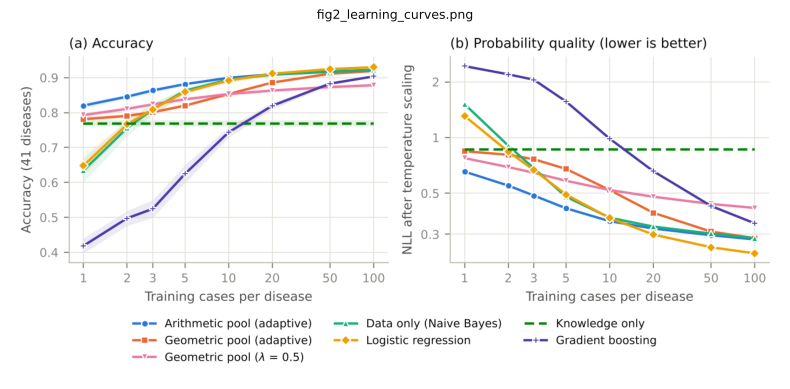

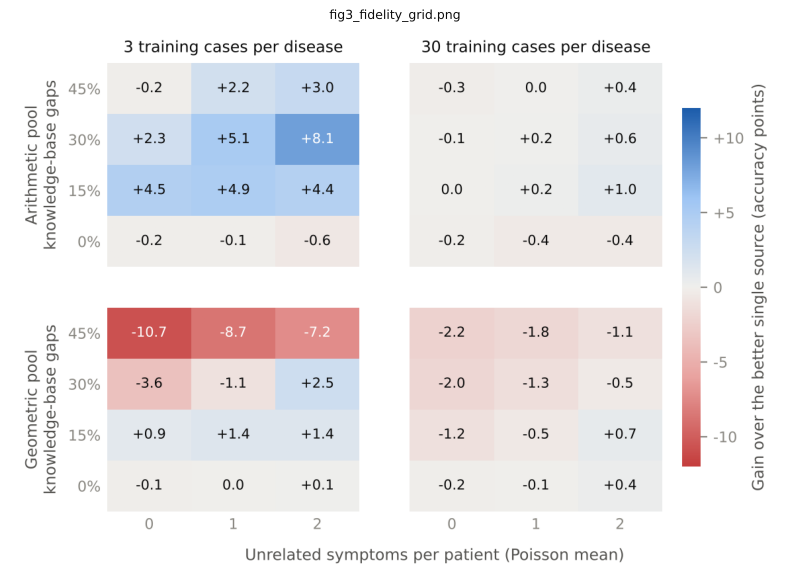

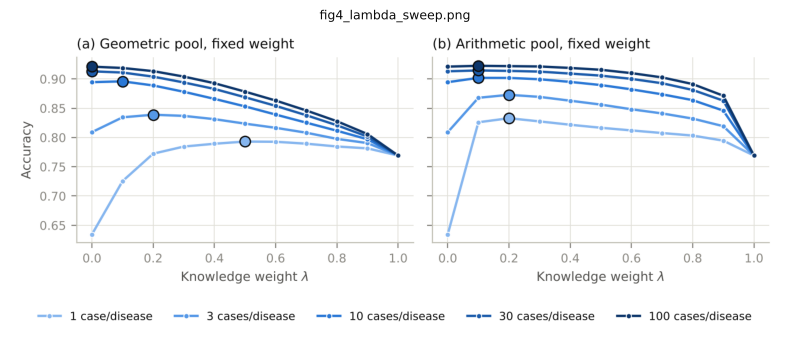

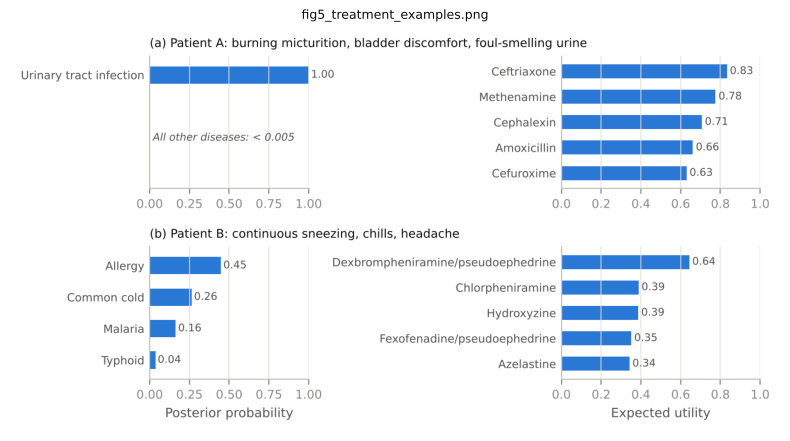

In [5]:
import matplotlib.pyplot as plt
for f in sorted((ROOT / "results" / "figures").glob("*.png")):
    img = plt.imread(f)
    plt.figure(figsize=(10, 10 * img.shape[0] / img.shape[1]))
    plt.imshow(img); plt.axis("off"); plt.title(f.name, fontsize=9)
    plt.show()